In [1]:
import torch
import math
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from batteryml.pipeline import Pipeline
from batteryml.pipeline import build_dataset
from batteryml.builders import FEATURE_EXTRACTORS, LABEL_ANNOTATORS
from batteryml.feature.base import BaseFeatureExtractor
from batteryml.label.base import BaseLabelAnnotator
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
!rm -rf cache

In [2]:
def plot_predictions_by_battery(y_true, y_pred, cell_ids, is_soh=True, smooth_alpha=None, ncols=2):
    """
    Plot predictions against ground truth, grouping batteries in a grid (two columns by default).
    
    y_true: array or list of ground-truth labels
    y_pred: array or list of predictions
    cell_ids: battery ID for each sample
    smooth_alpha: optional (e.g., 0.05); applies EMA smoothing to each prediction series
    ncols: number of grid columns (two by default, for layouts such as 2x2 or 3x2)
    """
    # Flatten inputs in case they are lists of batches or PyTorch tensors.
    if isinstance(y_true, list):
        y_true = np.concatenate([y.flatten() if isinstance(y, np.ndarray) else y.detach().cpu().numpy().flatten() for y in y_true])
    else:
        y_true = np.array(y_true).flatten()

    if isinstance(y_pred, list):
        y_pred = np.concatenate([p.flatten() if isinstance(p, np.ndarray) else p.detach().cpu().numpy().flatten() for p in y_pred])
    else:
        y_pred = np.array(y_pred).flatten()
        
    cell_ids = np.array(cell_ids).flatten()
    
    unique_cells = np.unique(cell_ids)
    num_cells = len(unique_cells)
    
    if num_cells == 0:
        print("There are no batteries to display.")
        return

    # Calculate the required number of rows automatically.
    nrows = math.ceil(num_cells / ncols)
    
    # Create the overall figure with subplots.
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows), squeeze=False)
    axes_flat = axes.flatten()  # Flatten the axes array for sequential iteration.
    
    ylabel = 'SOH' if is_soh else 'RUL (cycles)'
    
    for i, cell_id in enumerate(unique_cells):
        ax = axes_flat[i]
        mask = (cell_ids == cell_id)
        y_true_cell = y_true[mask]
        y_pred_cell = y_pred[mask]
        
        # Ground Truth
        ax.plot(y_true_cell, label='Ground truth', color='black', linewidth=2)
        
        # Predictions
        if smooth_alpha is not None:
            ax.plot(y_pred_cell, label='Raw prediction', color='crimson', alpha=0.3, linestyle='--')
            y_pred_smoothed = pd.Series(y_pred_cell).ewm(alpha=smooth_alpha, adjust=False).mean().to_numpy()
            ax.plot(y_pred_smoothed, label=f'EMA (α={smooth_alpha})', color='red', linewidth=1.8)
        else:
            ax.plot(y_pred_cell, label='Prediction', color='crimson', linestyle='--', linewidth=1.5)
            
        ax.set_xlabel('Cycle')
        ax.set_ylabel(ylabel)
        ax.set_title(f'Battery: {cell_id}')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    # Hide unused grid slots when the number of batteries is odd (e.g., 3 batteries in a 2x2 grid).
    for j in range(num_cells, len(axes_flat)):
        axes_flat[j].set_visible(False)
        
    plt.tight_layout()
    plt.show()

# State of health (SOH)

In [3]:
import numpy as np
import torch

def create_sliding_window_dataset_cnn_rul(
    cells, 
    window_size=5, 
    fixed_length=256,
    piecewise_cap=None  # Optional RUL cap to avoid overly large target values.
):
    X, y, cell_ids = [], [], []
    
    for cell_idx, cell in enumerate(cells):
        cell_identifier = getattr(cell, 'cell_id', f"Cell_{cell_idx}")
        cycle_matrices = []
        
        for cycle in cell.cycle_data:
            # Safely extract the raw arrays.
            def get_clean_array(obj, attr_name):
                val = getattr(obj, attr_name, [])
                if val is None:
                    return np.array([])
                if not isinstance(val, (list, tuple, np.ndarray)):
                    val = [val]
                clean_val = [x for x in val if x is not None]
                return np.array(clean_val, dtype=float)
            
            v = get_clean_array(cycle, 'voltage_in_V')
            c = get_clean_array(cycle, 'current_in_A')
            t = get_clean_array(cycle, 'time_in_s')
            
            # Normalize time so it always starts at 0, which avoids instability.
            t = t - t[0] if len(t) > 0 else t
            
            # Create an empty array for this cycle with shape (3 channels, fixed_length).
            cycle_matrix = np.zeros((3, fixed_length))
            
            # Interpolate the signals.
            if len(v) > 1 and len(c) > 1 and len(t) > 1:
                idx_new = np.linspace(0, 1, fixed_length)
                
                v_resampled = np.interp(idx_new, np.linspace(0, 1, len(v)), v)
                c_resampled = np.interp(idx_new, np.linspace(0, 1, len(c)), c)
                t_resampled = np.interp(idx_new, np.linspace(0, 1, len(t)), t)
                
                cycle_matrix[0, :] = v_resampled
                cycle_matrix[1, :] = c_resampled
                cycle_matrix[2, :] = t_resampled
                
            cycle_matrices.append(cycle_matrix)
            
        total_cycles = len(cycle_matrices)
        if total_cycles < window_size:
            continue

        # --- GENERATE WINDOWS AND RUL LABELS ---
        for i in range(total_cycles - window_size + 1):
            window = cycle_matrices[i : i + window_size]
            
            # window_array initially has shape (window_size, 3_channels, fixed_length).
            window_array = np.array(window)
            
            # REORDER DIMENSIONS FOR PYTORCH -> (channels, window, length).
            tensor_cnn = np.transpose(window_array, (1, 0, 2))
            X.append(tensor_cnn)
            
            # CALCULATE THE RUL LABEL.
            current_cycle_idx = i + window_size - 1
            rul_lineal = total_cycles - current_cycle_idx - 1
            
            # Apply piecewise RUL if a cap is defined.
            if piecewise_cap is not None:
                rul_final = min(rul_lineal, piecewise_cap)
            else:
                rul_final = rul_lineal
                
            y.append(float(rul_final))
            cell_ids.append(cell_identifier)
            
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32), np.array(cell_ids)

In [4]:
# =====================================================================
# 1. THE WORKAROUND: Dummy classes to satisfy the pipeline.
# =====================================================================
if 'DummyFeature' not in FEATURE_EXTRACTORS.class_mapping:
    @FEATURE_EXTRACTORS.register()
    class DummyFeature(BaseFeatureExtractor):
        def process_cell(self, cell): 
            return torch.randn(1)
        # Override __call__ to prevent torch.stack errors.
        def __call__(self, cells):
            return torch.randn(len(cells), 1)

if 'DummyLabel' not in LABEL_ANNOTATORS.class_mapping:
    @LABEL_ANNOTATORS.register()
    class DummyLabel(BaseLabelAnnotator):
        def process_cell(self, cell): 
            return torch.randn(1)
        def __call__(self, cells):
            return torch.randn(len(cells))

# Load the configuration.
pipeline = Pipeline(config_path='configs/baselines/sklearn/rf/calce_rf.yaml', workspace='workspace/calce_rf')

# Temporarily override the in-memory YAML configuration to use the dummy classes.
pipeline.config['feature'] = {'name': 'DummyFeature'}
pipeline.config['label'] = {'name': 'DummyLabel'}

Missing expected config fields: ['feature', 'label', 'feature_transformation', 'label_transformation']
workspace/calce_rf


In [5]:
# =====================================================================
# 2. SAFE DATA EXTRACTION
# =====================================================================
# build_dataset should now run in milliseconds without crashing.
dataset_dummy, raw_data = build_dataset(pipeline.config, device='cpu')

train_cells = raw_data['train_cells']
test_cells = raw_data['test_cells']

Reading test data: 100%|██████████| 4/4 [00:00<00:00,  6.84it/s]


In [6]:
# 4. Generate the final flattened arrays.
window = 5
feature_names = ['voltage_in_V', 'current_in_A', 'time_in_s']
X_train, y_train, train_cell_ids = create_sliding_window_dataset_cnn_rul(train_cells, window_size=window)
X_test, y_test, test_cell_ids = create_sliding_window_dataset_cnn_rul(test_cells, window_size=window)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape} | y_test shape: {y_test.shape}")

X_train shape: (9047, 3, 5, 256) | y_train shape: (9047,)
X_test shape: (5199, 3, 5, 256) | y_test shape: (5199,)


In [7]:
# Temporarily flatten: (N, 3, 5, 256) -> (N, 3840).
n_muestras, canales, alto, ancho = X_train.shape
X_train_flat = X_train.reshape(n_muestras, -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

# Scale the data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
X_test_scaled = scaler.transform(X_test_flat)

# Restore the original 4D shape for the CNN.
X_train = X_train_scaled.reshape(n_muestras, canales, alto, ancho)
X_test = X_test_scaled.reshape(X_test.shape[0], canales, alto, ancho)

## MLP (Pytorch)

In [8]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# 1. Convert to tensors, ensuring the float32 data type.
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

# 2. Create the datasets.
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# 3. Create the DataLoaders (set batch_size, e.g., 32 or 64).
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Tensor X_train shape: {X_train_tensor.shape}")

Tensor X_train shape: torch.Size([9047, 3, 5, 256])


In [9]:
import torch
import math
from torch import nn


def train_loop(model, dataloader, optimizer, device):
    model.train() 
    running_loss = 0.0
    
    for batch_x, batch_y in dataloader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        loss = model(batch_x, batch_y, return_loss=True)
        
        if torch.isinf(loss) or torch.isnan(loss):
            continue
            
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * batch_x.size(0)
        
    # Mean squared error (MSE) loss.
    epoch_loss = running_loss / len(dataloader.dataset)
    
    # Calculate the training RMSE.
    epoch_rmse = np.sqrt(epoch_loss)
    
    return epoch_loss, epoch_rmse



def test_loop(model, dataloader, device):
    """
    Evaluation loop for test/validation.
    """
    model.eval()  # Set the model to evaluation mode (disables dropout, etc.).
    running_loss = 0.0
    
    all_preds = []
    all_labels = []
    
    # Use PyTorch's standard MSELoss for evaluation.
    criterion = nn.MSELoss()
    
    with torch.no_grad():  # Disable gradient tracking to save memory and GPU resources.
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            
            # 1. Forward pass: get the predictions.
            # Keep return_loss=False (the default) so the model returns 'x'.
            predictions = model(batch_x, batch_y)
            
            # 2. Calculate the loss manually for this metric.
            loss = criterion(predictions.view(-1), batch_y.view(-1))
            running_loss += loss.item() * batch_x.size(0)
            
            # Store predictions and ground-truth values to calculate RMSE and plot the results.
            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(batch_y.cpu().numpy())
            
    epoch_loss = running_loss / len(dataloader.dataset)
    
    # Calculate the overall RMSE as the square root of MSELoss.
    rmse = np.sqrt(epoch_loss)
    
    return epoch_loss, rmse, np.array(all_preds), np.array(all_labels)

In [10]:
from batteryml.models.rul_predictors.cnn import CNNRULPredictor

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Entrenando en: {device}")

# Instantiate the model using the exact sizes of your 4D matrix
model = CNNRULPredictor(
    in_channels=3, 
    channels=16,          # Base filters; you can increase to 32 or 64 if you want more complexity
    input_height=5,       # Tu window_size
    input_width=256,      # Tu fixed_length interpolado
    kernel_size=(1, 5)    # Kernel rectangular para evitar sobre-reducir el eje Y (altura 5)
).to(device)

# Optimizador
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Main loop (example with 50 epochs)
epochs = 50

for epoch in range(epochs):
    # Ahora desempaquetamos dos valores
    train_loss, train_rmse = train_loop(model, train_loader, optimizer, device)
    
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Train RMSE: {train_rmse:.4f}")

# When finished, you can use 'test_preds' and 'test_labels' to draw your Ground Truth vs Prediction plots.

Entrenando en: cpu
Epoch [1/50] | Train RMSE: 504.1821
Epoch [10/50] | Train RMSE: 142.5102
Epoch [20/50] | Train RMSE: 133.4073
Epoch [30/50] | Train RMSE: 128.6771
Epoch [40/50] | Train RMSE: 123.7791
Epoch [50/50] | Train RMSE: 117.1240


In [11]:
model.eval()
# Evaluamos
test_loss, test_rmse, test_preds, test_labels = test_loop(model, test_loader, device)
print(f'test loss: {test_loss}, test_rmse: {test_rmse}')

test loss: 31420.206696055582, test_rmse: 177.25745878821456


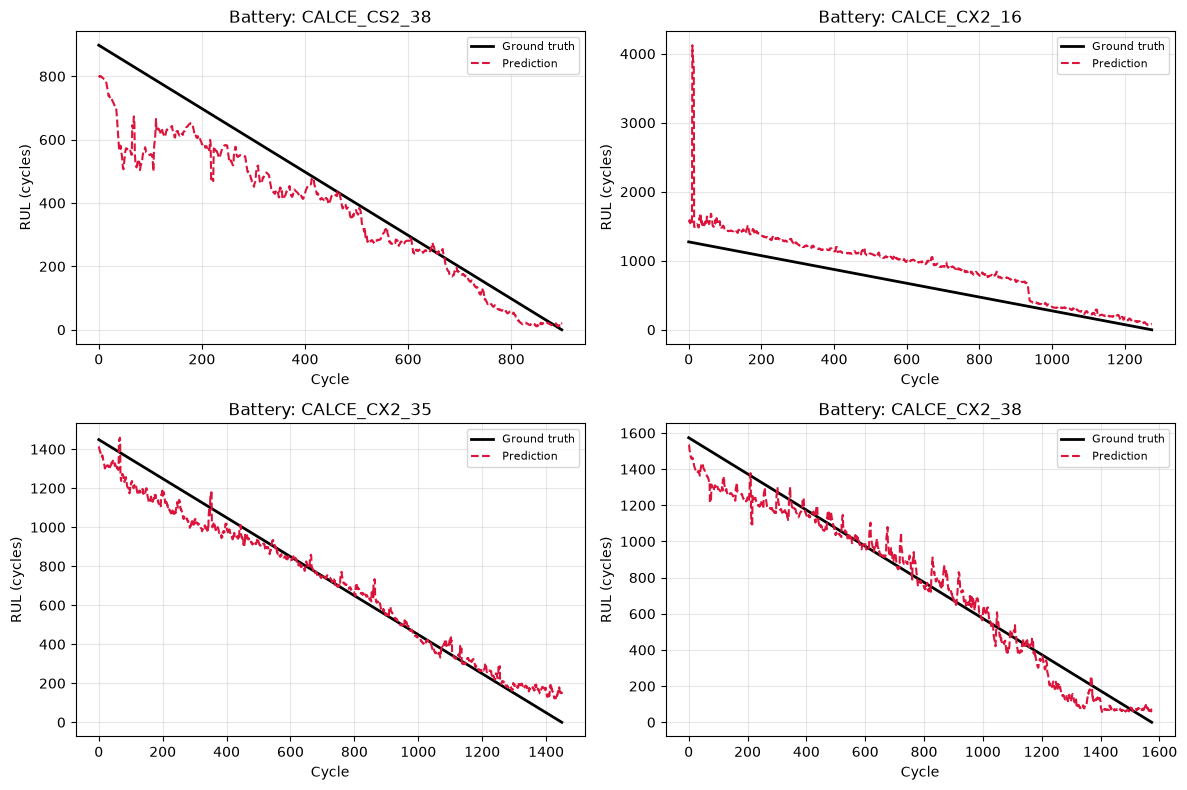

In [12]:
# plot_ground_truth_vs_predictions(predictions, y_test, is_soh=True)
predictions_flat = np.concatenate([p.flatten() for p in test_preds])
y_test_flat = np.concatenate([y.flatten() for y in test_labels])
plot_predictions_by_battery(y_test_flat, predictions_flat, cell_ids=test_cell_ids, is_soh=False)

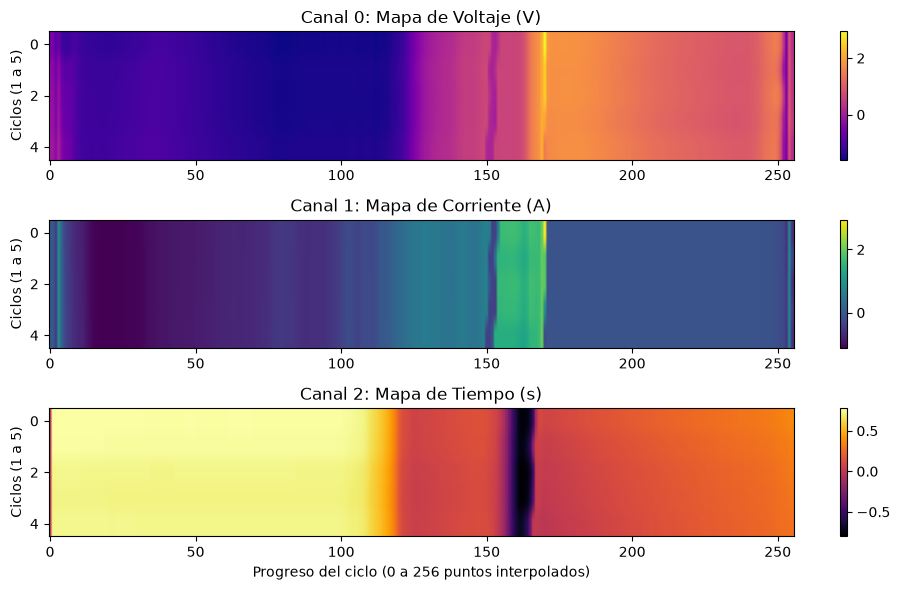

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Extraemos la primera muestra de entrenamiento (1 ventana de 5 ciclos)
# Forma esperada de X_train[0]: (3_canales, 5_alto, 256_ancho)
muestra = X_train[0] 

# Separamos los 3 canales
mapa_voltaje = muestra[0]
mapa_corriente = muestra[1]
mapa_tiempo = muestra[2]

fig, axes = plt.subplots(3, 1, figsize=(10, 6))

# Dibujamos el Voltaje
im0 = axes[0].imshow(mapa_voltaje, aspect='auto', cmap='plasma')
axes[0].set_title('Canal 0: Mapa de Voltaje (V)')
axes[0].set_ylabel('Ciclos (1 a 5)')
fig.colorbar(im0, ax=axes[0])

# Dibujamos la Corriente
im1 = axes[1].imshow(mapa_corriente, aspect='auto', cmap='viridis')
axes[1].set_title('Canal 1: Mapa de Corriente (A)')
axes[1].set_ylabel('Ciclos (1 a 5)')
fig.colorbar(im1, ax=axes[1])

# Dibujamos el Tiempo
im2 = axes[2].imshow(mapa_tiempo, aspect='auto', cmap='inferno')
axes[2].set_title('Canal 2: Mapa de Tiempo (s)')
axes[2].set_ylabel('Ciclos (1 a 5)')
axes[2].set_xlabel('Progreso del ciclo (0 a 256 puntos interpolados)')
fig.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()